# Week 4 Hands-on– When Can I Trust an MD Trajectory?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Hossein_Moein_HW3 import max_lag


In [1]:
import numpy as np
import matplotlib.pyplot as plt


def initialize_lattice(n_particles, box_length):
    """Place particles on a square lattice."""
    n_side = int(np.ceil(np.sqrt(n_particles)))
    spacing = box_length / n_side
    coordinates = []

    for iy in range(n_side):
        for ix in range(n_side):
            if len(coordinates) >= n_particles:
                break
            coordinates.append([(ix + 0.5) * spacing,
                                (iy + 0.5) * spacing])
        if len(coordinates) >= n_particles:
            break

    return np.array(coordinates, dtype=float)


def lj_forces(positions_wrapped, box_length):
    """Return Lennard-Jones forces and potential energy in reduced units.

    This small educational system evaluates all particle pairs. Periodic
    boundaries are handled with the minimum-image convention.
    """
    r = positions_wrapped

    # Pair displacement r_i - r_j
    dr = r[:, None, :] - r[None, :, :]
    dr -= box_length * np.rint(dr / box_length)

    r2 = np.sum(dr**2, axis=2)
    np.fill_diagonal(r2, np.inf)

    inv_r2 = 1.0 / r2
    inv_r6 = inv_r2**3

    # F_ij = 24 [2 r^-14 - r^-8] r_ij
    prefactor = 24.0 * inv_r2 * (2.0 * inv_r6**2 - inv_r6)
    prefactor[np.isinf(r2)] = 0.0
    forces = np.sum(prefactor[:, :, None] * dr, axis=1)

    # Pair potential; factor 1/2 removes double counting
    pair_u = 4.0 * (inv_r6**2 - inv_r6)
    np.fill_diagonal(pair_u, 0.0)
    potential_energy = 0.5 * np.sum(pair_u)

    return forces, potential_energy


def instantaneous_temperature(velocities):
    """Return the instantaneous reduced temperature and kinetic energy."""
    kinetic_energy = 0.5 * np.sum(velocities**2)
    degrees_of_freedom = velocities.size
    temperature = 2.0 * kinetic_energy / degrees_of_freedom
    return temperature, kinetic_energy


def run_lj_md(
    ensemble='NVE',
    target_temperature=1.0,
    initial_temperature=0.5,
    dt=0.005,
    total_time=60.0,
    n_particles=36,
    density=0.65,
    sample_dt=0.05,
    seed=504,
    collision_rate=1.0,
):
    """Run a small 2D Lennard-Jones simulation with velocity Verlet.

    NVE: ordinary conservative velocity-Verlet dynamics.
    NVT: the same dynamics plus a simple Andersen thermostat. Each particle
         has a small probability collision_rate*dt of being reassigned a
         velocity drawn from the target thermal distribution.

    The thermostat implementation is supplied for this exercise; students are
    not expected to derive or modify it.
    """
    ensemble = ensemble.upper()
    if ensemble not in {'NVE', 'NVT'}:
        raise ValueError("ensemble must be 'NVE' or 'NVT'")

    box_length = np.sqrt(n_particles / density)
    positions = initialize_lattice(n_particles, box_length)
    positions_unwrapped = positions.copy()

    rng = np.random.default_rng(seed)

    velocities = rng.normal(size=(n_particles, 2))
    velocities -= velocities.mean(axis=0)

    current_temperature, _ = instantaneous_temperature(velocities)
    velocities *= np.sqrt(initial_temperature / current_temperature)

    forces, potential_energy = lj_forces(positions, box_length)

    n_steps = int(round(total_time / dt))
    sample_every = max(1, int(round(sample_dt / dt)))

    times = []
    temperatures = []
    potential_per_particle = []
    kinetic_per_particle = []
    total_per_particle = []
    trajectory = []

    for step in range(n_steps + 1):
        if step % sample_every == 0:
            temperature, kinetic_energy = instantaneous_temperature(velocities)
            times.append(step * dt)
            temperatures.append(temperature)
            potential_per_particle.append(potential_energy / n_particles)
            kinetic_per_particle.append(kinetic_energy / n_particles)
            total_per_particle.append((kinetic_energy + potential_energy) / n_particles)
            trajectory.append(positions_unwrapped.copy())

        if step == n_steps:
            break

        # Velocity-Verlet integration
        velocities += 0.5 * dt * forces
        positions_unwrapped += dt * velocities
        positions = np.mod(positions_unwrapped, box_length)

        new_forces, new_potential_energy = lj_forces(positions, box_length)
        velocities += 0.5 * dt * new_forces

        # Simple Andersen thermostat for NVT
        if ensemble == 'NVT':
            collisions = rng.random(n_particles) < collision_rate * dt
            n_collisions = int(collisions.sum())
            if n_collisions:
                velocities[collisions] = rng.normal(
                    scale=np.sqrt(target_temperature),
                    size=(n_collisions, 2),
                )

        forces = new_forces
        potential_energy = new_potential_energy

    return {
        'ensemble': ensemble,
        'time': np.array(times),
        'temperature': np.array(temperatures),
        'potential_per_particle': np.array(potential_per_particle),
        'kinetic_per_particle': np.array(kinetic_per_particle),
        'total_per_particle': np.array(total_per_particle),
        'trajectory': np.array(trajectory),
        'box_length': box_length,
    }


def normalized_autocorrelation(values, max_lag=None):
    """Normalized autocorrelation C(k) of one scalar observable time series."""
    x = np.asarray(values, dtype=float)
    x = x - x.mean()

    if max_lag is None:
        max_lag = len(x) - 1

    corr = np.correlate(x, x, mode='full')[len(x)-1:]
    normalization = np.arange(len(x), 0, -1)
    corr = corr / normalization
    corr = corr / corr[0]
    return corr[:max_lag + 1]


def block_means(values, n_blocks=10):
    """Split a time series into equal contiguous blocks and return block means."""
    values = np.asarray(values, dtype=float)
    n_per_block = len(values) // n_blocks
    trimmed = values[:n_per_block * n_blocks]
    return trimmed.reshape(n_blocks, n_per_block).mean(axis=1)


بیا این قسمت از کد Andersen Thermostat رو خط‌به‌خط با یک مثال عددی بررسی کنیم. هدف این بخش اینه که در شبیه‌سازی NVT، دمای سیستم به‌طور آماری نزدیک دمای هدف باقی بمونه.

فرض کن سیستم ما ۳۶ ذره داره و پارامترها این‌ها هستن:

```
n_particles = 36collision_rate = 1.0dt = 0.005target_temperature = 1.0
```

## 1. بررسی نوع Ensemble

```
if ensemble == 'NVT':
```

یعنی فقط اگر شبیه‌سازی از نوع `NVT` باشه، ترموستات فعال می‌شه.

- NVT: ترموستات فعال است و می‌تواند سرعت ذرات را تغییر دهد.
- NVE: ترموستات غیرفعال است و ذرات فقط تحت تأثیر نیروهای فیزیکی حرکت می‌کنند.

## 2. انتخاب تصادفی ذرات برای Collision

```
collisions = rng.random(n_particles) < collision_rate * dt
```

این خط دو کار انجام می‌ده.

قسمت اول:

```
rng.random(n_particles)
```

برای هر یک از ۳۶ ذره، یک عدد تصادفی بین صفر و یک تولید می‌کنه.

مثلاً برای ۵ ذره:

```
[0.72, 0.003, 0.51, 0.001, 0.89]
```

قسمت دوم:

```
collision_rate * dt
```

احتمال Collision هر ذره در یک Time Step رو تعیین می‌کنه:

\\[ P=\nu\Delta t=1.0\times0.005=0.005 \\]

یعنی هر ذره در هر Time Step احتمال ۰٫۵ درصد داره که توسط ترموستات انتخاب بشه.

قسمت سوم:

علامت `<` بررسی می‌کنه کدوم عدد تصادفی از 0.005 کوچک‌تره.

مثال انتخاب ذرات

| ذره | عدد تصادفی | Collision |
| --- | ---------- | --------- |
| 1   | 0.720      | False     |
| 2   | 0.003      | True      |
| 3   | 0.510      | False     |
| 4   | 0.001      | True      |
| 5   | 0.890      | False     |

خروجی `collisions` در این مثال:

```
[False, True, False, True, False]
```

پس فقط ذرات شماره ۲ و ۴ انتخاب شدن.

نکته: این Collision یک برخورد فیزیکی واقعی بین دو ذره نیست؛ بلکه یک برخورد مجازی با Heat Bath است.

## 3. شمارش تعداد Collisionها

```
n_collisions = int(collisions.sum())
```

اینجا NumPy تعداد `True`ها رو می‌شماره.

چون در محاسبات عددی:

- `True = 1`
- `False = 0`

پس:

```
[False, True, False, True, False]
```

نتیجه:

```
n_collisions = 2
```

یعنی در این Time Step، دو ذره انتخاب شدن.

## 4. بررسی اینکه Collision رخ داده یا نه

```
if n_collisions:
```

این خط معادل اینه:

```
if n_collisions > 0:
```

اگر حتی یک ذره انتخاب شده باشه، وارد بخش بعدی می‌شیم.

اگر هیچ ذره‌ای انتخاب نشده باشه، کد تغییر سرعت رو اجرا نمی‌کنه.

## 5. اختصاص سرعت جدید به ذرات انتخاب‌شده

```
velocities[collisions] = rng.normal(    scale=np.sqrt(target_temperature),    size=(n_collisions, 2),)
```

این مهم‌ترین بخش ترموستاته.

### قسمت اول: `rng.normal`

این تابع اعداد تصادفی از یک Normal (Gaussian) Distribution تولید می‌کنه.

به‌جای اینکه سرعت کاملاً دلخواه انتخاب بشه، از توزیع آماری متناسب با دمای هدف استفاده می‌کنیم.

### قسمت دوم: `scale=np.sqrt(target_temperature)`

در NumPy، پارامتر `scale` برابر Standard Deviation توزیع نرماله.

چون در Reduced Units داریم:

\\[ m=k_B=1 \\]

و توزیع سرعت باید واریانس زیر رو داشته باشه:

\\[ \sigma_v^2=\frac{k_BT}{m}=T \\]

پس:

\\[ \boxed{\sigma_v=\sqrt{T\_{\mathrm{target}}}} \\]

برای دمای هدف ۱:

```
scale = np.sqrt(1.0)  # 1.0
```

بنابراین سرعت‌های جدید از توزیع زیر میان:

\\[ v_x,v_y\sim\mathcal N(0,1) \\]

یعنی میانگین سرعت در هر جهت صفر و انحراف معیار آن ۱ است.

### قسمت سوم: `size=(n_collisions, 2)`

چون شبیه‌سازی دوبعدیه، هر ذره دو مؤلفه سرعت داره:

\\[ \vec v_i=(v_x,v_y) \\]

در مثال ما دو ذره انتخاب شده بودن:

```
n_collisions = 2
```

پس:

```
size = (2, 2)
```

خروجی فرضی:

```
[    [ 0.4, -1.2],    [-0.8,  0.6]]
```

یعنی برای هر ذره انتخاب‌شده یک سرعت جدید دوبعدی تولید می‌شه.

### قسمت چهارم: `velocities[collisions] = ...`

فرض کن سرعت اولیه پنج ذره این باشه:

```
velocities = np.array([    [ 1.0,  0.5],    [ 2.0,  1.5],    [-0.5,  0.3],    [ 1.8, -1.0],    [ 0.2,  0.7]])
```

بعد از اجرای ترموستات:

قبل و بعد از Collision

| ذره | سرعت قبلی   | سرعت جدید   |
| --- | ----------- | ----------- |
| 1   | (1.0, 0.5)  | (1.0, 0.5)  |
| 2   | (2.0, 1.5)  | (0.4, −1.2) |
| 3   | (−0.5, 0.3) | (−0.5, 0.3) |
| 4   | (1.8, −1.0) | (−0.8, 0.6) |
| 5   | (0.2, 0.7)  | (0.2, 0.7)  |

فقط سرعت ذرات ۲ و ۴ تغییر کرده. سایر ذرات سرعت قبلی خودشون رو حفظ می‌کنن.

اما چرا این کار دما رو کنترل می‌کنه؟

چون سرعت‌های جدید از توزیعی میان که متوسط انرژی جنبشی مورد انتظارش با دمای هدف سازگاره.

اگر سیستم خیلی گرم باشه، این جایگزینی‌های تصادفی به‌طور متوسط انرژی جنبشی رو کاهش می‌دن؛ اگر سرد باشه، به‌طور متوسط افزایش می‌دن.

در نتیجه دما به‌مرور حول `target_temperature` نوسان می‌کنه، نه اینکه دقیقاً در هر لحظه برابر اون باشه.

## 6. به‌روزرسانی نیروها

```
forces = new_forces
```

این خط دیگر بخشی از Andersen Thermostat نیست و در هر دو حالت NVT و NVE اجرا می‌شه.

در قسمت قبلی الگوریتم Velocity-Verlet، ذرات جابه‌جا شدن و نیروهای جدید محاسبه شدن:

```
new_forces, new_potential_energy = lj_forces(    positions, box_length)
```

پس:

```
forces = new_forces
```

یعنی نیروهای محاسبه‌شده در موقعیت جدید رو برای Time Step بعدی ذخیره کن.

مثلاً:

\\[ F(t)\longrightarrow F(t+\Delta t) \\]

در گام بعدی، الگوریتم از همین نیروی جدید استفاده می‌کنه.

## 7. به‌روزرسانی انرژی پتانسیل

```
potential_energy = new_potential_energy
```

این خط هم در NVE و هم NVT اجرا می‌شه.

چون موقعیت ذرات تغییر کرده، انرژی پتانسیل Lennard-Jones هم ممکنه تغییر کرده باشه.

پس مقدار جدید رو ذخیره می‌کنیم تا در Time Step بعدی ازش استفاده بشه.

## خلاصه کل کد در یک نگاه

آیا Ensemble برابر NVT است؟

اگر بله: برای هر ذره یک عدد تصادفی تولید کن

بررسی کن: `random < collision_rate * dt`

ذرات انتخاب‌شده را بشمار و به آن‌ها سرعت جدید بده

در هر دو Ensemble: نیرو و انرژی پتانسیل جدید را ذخیره کن

نکته نهایی: در Andersen Thermostat، خود برخوردهای مجازی باعث تغییر سرعت می‌شن، اما نیروی بین ذرات همچنان توسط پتانسیل Lennard-Jones و الگوریتم Velocity-Verlet محاسبه می‌شه. این دو سازوکار در کنار هم حرکت سیستم NVT رو ایجاد می‌کنن.

## Part 1– NVE versus NVT


In [6]:
# Simulation parameters
params = dict(
    initial_temperature=0.5,
    dt=0.005,
    total_time=60.0,
    n_particles=36,
    density=0.65,
    sample_dt=0.05,
    seed=504,
)

# TODO 1: run the NVE simulation
run_nve = run_lj_md(ensemble='NVE', **params)

# TODO 2: run the NVT simulation with target_temperature=1.0
run_nvt = run_lj_md(ensemble='NVT',target_temperature=1, **params)



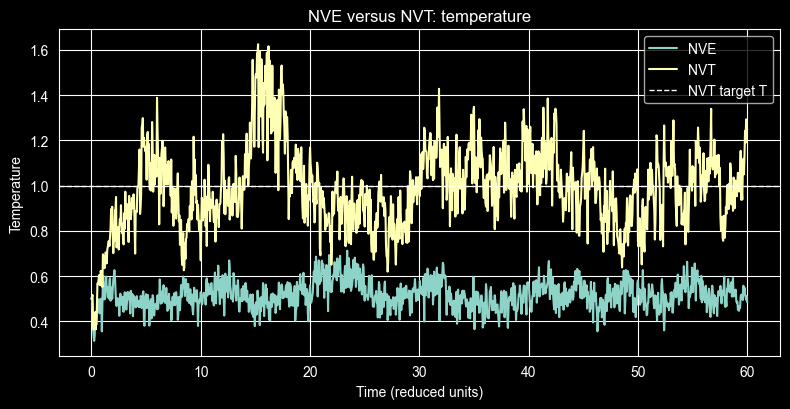

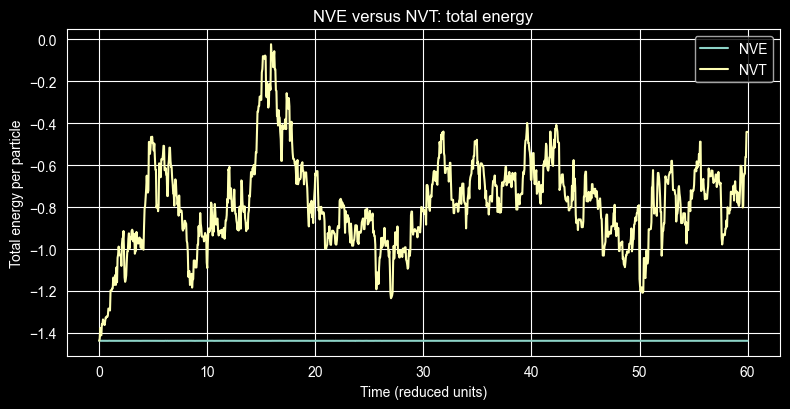

In [7]:
plt.figure(figsize=(8, 4.2))
# TODO: plot temperature versus time for both NVE and NVT
plt.plot(run_nve['time'], run_nve['temperature'],label='NVE')

plt.plot(run_nvt['time'], run_nvt['temperature'],label='NVT')


plt.axhline(1.0, linestyle='--', linewidth=1, label='NVT target T')
plt.xlabel('Time (reduced units)')
plt.ylabel('Temperature')
plt.title('NVE versus NVT: temperature')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.2))
# TODO: plot total energy per particle versus time for both NVE and NVT
plt.plot(run_nve['time'], run_nve['total_per_particle'],label='NVE')

plt.plot(run_nvt['time'], run_nvt['total_per_particle'],label='NVT')


plt.xlabel('Time (reduced units)')
plt.ylabel('Total energy per particle')
plt.title('NVE versus NVT: total energy')
plt.legend()
plt.tight_layout()
plt.show()


Answers to Part 1.2 — Compare the two runs
These are the expected interpretations of the plots. The final conclusions should be checked against your actual graphs.

a. What indicates that the NVE trajectory behaves as expected for conservative dynamics?

The total energy per particle should remain approximately constant over time, without significant systematic drift. This indicates that the simulation approximately conserves energy.

b. Why is total energy not expected to remain constant in NVT?

Because the Andersen thermostat randomly reassigns particle velocities, allowing energy exchange with a virtual heat bath. Therefore, the system's total energy can fluctuate.

c. Does the NVT temperature fluctuate around the target, or is it fixed exactly at the target?

The NVT temperature fluctuates around the target value of \(T=1.0\), rather than remaining exactly constant.

## Part 2– Equilibration versus production

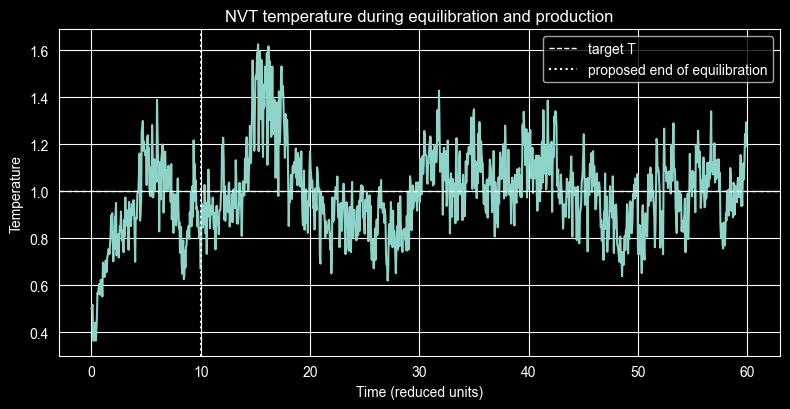

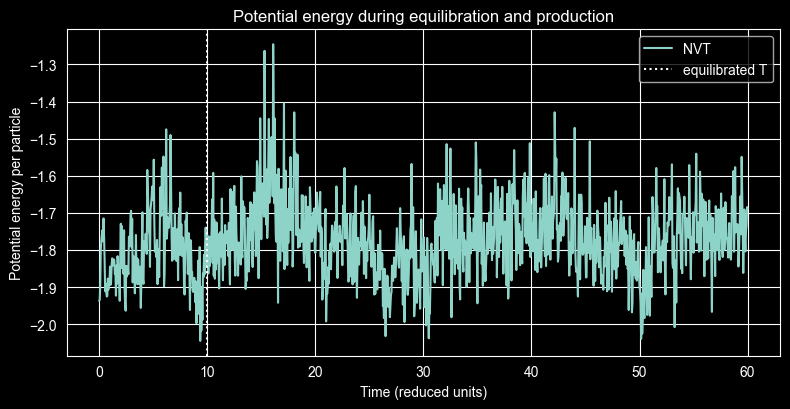

In [8]:
t_eq = 10.0
plt.figure(figsize=(8, 4.2))
plt.plot(run_nvt['time'], run_nvt['temperature'])
plt.axhline(1.0, linestyle='--', linewidth=1, label='target T')
plt.axvline(t_eq, linestyle=':', linewidth=1.5, label='proposed end of equilibration')
plt.xlabel('Time (reduced units)')
plt.ylabel('Temperature')
plt.title('NVT temperature during equilibration and production')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.2))
# TODO: plot potential energy per particle versus time
plt.plot(run_nvt['time'], run_nvt['potential_per_particle'],label='NVT')
# TODO: add a vertical line at t_eq
plt.axvline(t_eq, linestyle=':', linewidth=1.5, label='End of equilibration (t = 10)')

plt.xlabel('Time (reduced units)')
plt.ylabel('Potential energy per particle')
plt.title('Potential energy during equilibration and production')
plt.legend()
plt.tight_layout()
plt.show()


Answer:

what changes before and after t = 10, and why is it useful to exclude the early relaxation
period from production statistics?

Before \(t=10\), the system undergoes initial relaxation from its starting configuration. The temperature approaches the target value of \(T=1.0\), while the potential energy adjusts as the particles rearrange.

After \(t=10\), the temperature is expected to fluctuate around the target, and the potential energy should fluctuate around a relatively stable average without a strong systematic trend.

Excluding the initial relaxation period is important because it contains non-equilibrium data that could bias the calculated equilibrium averages. Therefore, \(t_{\mathrm{eq}}=10\) can be considered a reasonable working boundary if both plots show approximately stationary behavior afterward.


## Part 3– Calculate a production average

In [16]:
run_nvt_potential = run_nvt['potential_per_particle']
run_nvt_potential[10:]

array([-1.82596805, -1.91116435, -1.8902111 , ..., -1.73523353,
       -1.68460102, -1.68974253])

In [19]:
## Wrong answer
# TODO 1: Boolean mask selecting the NVT production region t >= t_eq
production_mask = run_nvt_potential[10:]

u_per_particle = run_nvt['potential_per_particle']
u_production = production_mask

# TODO 2: calculate the full-trajectory and production-only means
mean_u_all = np.mean(u_per_particle)
mean_u_prod = np.mean(u_production)

print(f'Mean U/N using full trajectory: {mean_u_all:.5f}')
print(f'Mean U/N using production only: {mean_u_prod:.5f}')
print(f'Difference: {mean_u_all - mean_u_prod:+.5f}')



### Why: t_10 maybe is the first 200 elemnts of potential but you are choosing first 10 elemets here

Mean U/N using full trajectory: -1.77273
Mean U/N using production only: -1.77242
Difference: -0.00031


In [23]:
# TODO 1: Boolean mask selecting the NVT production region t >= t_eq
production_mask = run_nvt['time'] >= t_eq

u_per_particle = run_nvt['potential_per_particle']
u_production = u_per_particle[production_mask]

# TODO 2: calculate the full-trajectory and production-only means
mean_u_all = np.mean(u_per_particle)
mean_u_prod = np.mean(u_production)

print(f'Mean U/N using full trajectory: {mean_u_all:.5f}')
print(f'Mean U/N using production only: {mean_u_prod:.5f}')
print(f'Difference: {mean_u_all - mean_u_prod:+.5f}')


Mean U/N using full trajectory: -1.77273
Mean U/N using production only: -1.76549
Difference: -0.00724


Explain why the production-only estimate is scientifically preferable even if the two numerical values
are fairly close in this particular run


The production-only estimate is scientifically preferable because it excludes the initial equilibration period, during which the system is still relaxing toward equilibrium. Including this non-equilibrium data could bias the calculated average potential energy per particle. Even if the two numerical estimates are close in this particular simulation, excluding the equilibration period provides a more reliable estimate of the equilibrium observable, assuming the chosen equilibration boundary is appropriate.

## Part 4– Autocorrelation of a specific observable

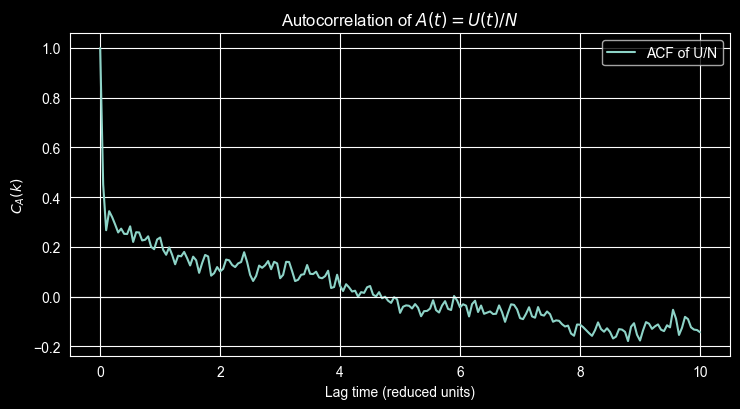

First lag below 1/e: 0.100 time units


In [29]:
sample_interval = run_nvt['time'][1] - run_nvt['time'][0]

# TODO 1: calculate C_A(k) for the production U/N time series.
# Use at most 200 lags.
acf_u = normalized_autocorrelation(u_production,max_lag=200)

lag_time = np.arange(len(acf_u)) * sample_interval

plt.figure(figsize=(7.5, 4.2))
# TODO 2: plot autocorrelation versus lag_time
plt.plot(lag_time, acf_u,label='ACF of U/N')

plt.axhline(0, linewidth=0.8)
plt.xlabel('Lag time (reduced units)')
plt.ylabel(r'$C_A(k)$')
plt.title(r'Autocorrelation of $A(t)=U(t)/N$')
plt.tight_layout()
plt.legend()
plt.show()

# Optional descriptive number: first lag where C_A falls below 1/e
below = np.where(acf_u < np.exp(-1))[0]
if len(below) > 0:
    first_index = below[0]
    print(f'First lag below 1/e: {lag_time[first_index]:.3f} time units')
else:
    print('C_A did not fall below 1/e in the plotted range.')


**a. What specific quantity is being autocorrelated?**

The potential energy per particle, \(A(t)=U(t)/N\), measured during the NVT production trajectory (\(t\geq10\)).

**b. What does decay of \(C_A(k)\) tell you about the independence of neighboring stored values?**

The decay indicates that the correlation between potential-energy measurements decreases as the time separation increases. Measurements at short time intervals are correlated, while those separated by longer intervals become less correlated.

**c. Why does saving frames more frequently not necessarily provide proportionally more independent information?**

Because closely spaced frames often contain highly correlated measurements. Saving more frames increases the number of stored data points, but not necessarily the amount of statistically independent information.

##  Block averaging and uncertainty

Block means:
[-1.76313898 -1.68142245 -1.78282465 -1.84589806 -1.77304435 -1.74044518
 -1.73558225 -1.79993608 -1.79315946 -1.74021128]

Production mean U/N: -1.76549
Naive SE:             0.00316
Block-based SE:       0.01415


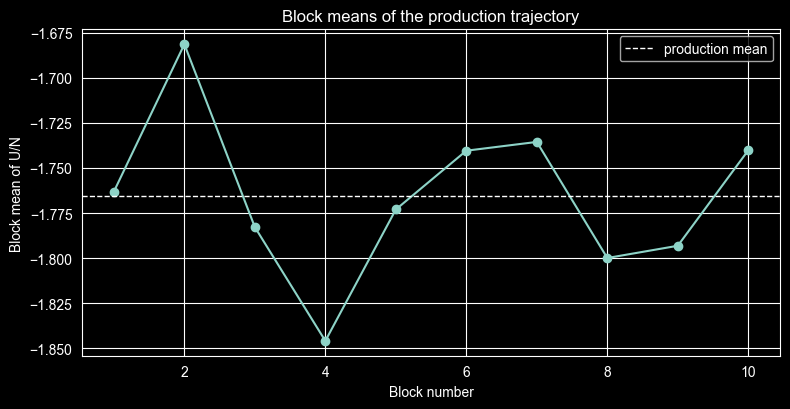

In [31]:
n_blocks = 10

# TODO 1: calculate the 10 block means
u_block_means = block_means(u_production,n_blocks=10)

# Naive SE: assumes every stored production frame is independent
naive_se = np.std(u_production, ddof=1) / np.sqrt(len(u_production))

# TODO 2: block-based SE from the spread of the block means
block_se = np.std(u_block_means, ddof=1) / np.sqrt(n_blocks)

print('Block means:')
print(u_block_means)
print(f'\nProduction mean U/N: {np.mean(u_production):.5f}')
print(f'Naive SE:             {naive_se:.5f}')
print(f'Block-based SE:       {block_se:.5f}')

plt.figure(figsize=(8, 4.2))
plt.plot(np.arange(1, n_blocks + 1), u_block_means, marker='o')
plt.axhline(np.mean(u_production), linestyle='--', linewidth=1, label='production mean')
plt.xlabel('Block number')
plt.ylabel('Block mean of U/N')
plt.title('Block means of the production trajectory')
plt.legend()
plt.tight_layout()
plt.show()


a. Which uncertainty estimate is larger?

The block-based standard error (0.01415) is approximately 4.48 times larger than the naive standard error (0.00316).

b. Why does ignoring time correlation tend to underestimate uncertainty?

Consecutive MD frames are temporally correlated and therefore do not represent independent samples. The naive method overestimates the effective number of independent observations, resulting in an artificially small standard error. Block averaging reduces this problem by analyzing averages over longer time intervals.

c. Why should the block duration be long compared with the correlation time?

Blocks should be sufficiently long for their averages to be approximately independent. If blocks are shorter than the characteristic correlation time, neighboring block means remain correlated, and the block-based standard error may also underestimate the true uncertainty.



بیا Part 5 رو از صفر و با ارتباط مستقیم به Part 3 و Part 4 توضیح بدیم. این بخش یکی از مهم‌ترین مفاهیم Statistical Analysis در Molecular Dynamics هست.

هدف اصلی اینه که بفهمیم:

وقتی از شبیه‌سازی MD یک میانگین محاسبه می‌کنیم، چقدر می‌تونیم به دقت اون میانگین اعتماد کنیم؟

# 1. اصلاً چرا به Block Averaging نیاز داریم؟

در Part 3 میانگین انرژی پتانسیل به‌ازای هر ذره رو حساب کردی:

\\[ A(t)=\frac{U(t)}{N} \\]

و بعد:

\\[ \bar A=\frac{1}{N\_{\mathrm{frames}}}\sum\_{i=1}^{N\_{\mathrm{frames}}}A_i \\]

مثلاً فرض کن نتیجه شده:

\\[ \bar A=-1.75 \\]

اما یک سؤال مهم باقی مونده:

آیا مقدار واقعی میانگین تعادلی به −1.75 نزدیکه؟ یا ممکنه با شبیه‌سازی طولانی‌تر مقدار متفاوتی به دست بیاریم؟

برای پاسخ به این سؤال باید Statistical Uncertainty رو تخمین بزنیم.

## 2. ارتباط با Autocorrelation در Part 4

در Part 4 یاد گرفتی که داده‌های پشت‌سرهم MD معمولاً مستقل نیستن.

مثلاً:

| Time  | \\(U/N\\) |
| ----- | --------- |
| 10.00 | −1.80     |
| 10.05 | −1.79     |
| 10.10 | −1.78     |
| 10.15 | −1.80     |
| 10.20 | −1.77     |

این مقادیر خیلی شبیه هم هستن، چون سیستم فقط مدت کوتاهی حرکت کرده.

بنابراین پنج اندازه‌گیری داری، ولی الزاماً پنج نمونه مستقل از وضعیت تعادلی سیستم نداری.

این دقیقاً مشکلیه که Block Averaging سعی می‌کنه حل کنه.

# 3. Block Averaging چطور کار می‌کنه؟

در Homework ازت خواسته شده داده‌های Production رو به ۱۰ بلوک متوالی و هم‌اندازه تقسیم کنی.

در شبیه‌سازی تو:

- Production از \\(t=10\\) تا \\(t=60\\) است.
- `sample_dt = 0.05`
- تعداد فریم‌های Production برابر 1001 است.

تابع `block_means` با ۱۰ بلوک، ۱۰۰ فریم در هر بلوک قرار می‌ده و یک فریم اضافه رو از انتها کنار می‌ذاره.

تقسیم ۱۰۰۰ فریم به ۱۰ بلوک

B1

100 frames

B2

100 frames

B3

100 frames

B4

100 frames

B5

100 frames

B6

100 frames

B7

100 frames

B8

100 frames

B9

100 frames

B10

100 frames

هر بلوک شامل ۱۰۰ اندازه‌گیری متوالی است؛ مدت هر بلوک حدود ۵ واحد زمانی است.

برای هر بلوک یک میانگین محاسبه می‌کنیم:

\\[ \bar A_b=\frac{1}{n_b}\sum\_{i\in b}A_i \\]

مثلاً ممکنه میانگین بلوک‌ها این‌طور باشه:

| Block | Mean \\(U/N\\) |
| ----- | -------------- |
| 1     | −1.72          |
| 2     | −1.78          |
| 3     | −1.74          |
| 4     | −1.81          |
| 5     | −1.76          |
| 6     | −1.70          |
| 7     | −1.79          |
| 8     | −1.75          |
| 9     | −1.73          |
| 10    | −1.77          |

این اعداد صرفاً مثال آموزشی هستن، نه خروجی واقعی شبیه‌سازی تو.

حالا به‌جای بررسی تک‌تک ۱۰۰۰ فریم، تغییرات میانگین این ۱۰ بلوک رو بررسی می‌کنیم.

نکته اصلی: هدف این نیست که داده‌ها رو حذف کنیم؛ هدف اینه که با میانگین‌گیری در بازه‌های زمانی طولانی‌تر، اثر Correlation بین فریم‌های نزدیک رو کاهش بدیم.

# 4. تفاوت Standard Deviation و Standard Error

این قسمت رو باید کاملاً متوجه بشی.

Standard Deviation (SD) می‌گه داده‌ها چقدر اطراف میانگین پراکنده هستن.

Standard Error (SE) می‌گه میانگینی که محاسبه کردی چقدر عدم‌قطعیت آماری داره.

در این تمرین دو روش برای تخمین SE داریم.

## روش اول: Naive Standard Error

\\[ \boxed{SE\_{\mathrm{naive}}=\frac{s\_{\mathrm{frames}}}{\sqrt{N\_{\mathrm{frames}}}}} \\]

اینجا:

- \\(s\_{\mathrm{frames}}\\): انحراف معیار تمام فریم‌های Production
- \\(N\_{\mathrm{frames}}\\): تعداد تمام فریم‌های Production

فرض کن:

\\[ s\_{\mathrm{frames}}=0.15,\qquad N\_{\mathrm{frames}}=1000 \\]

پس:

\\[ SE\_{\mathrm{naive}}=\frac{0.15}{\sqrt{1000}} \approx0.0047 \\]

مشکل کجاست؟

این فرمول فرض می‌کنه هر ۱۰۰۰ فریم مستقل هستن.

ولی از Part 4 می‌دونیم که فریم‌های نزدیک معمولاً Correlated هستن.

پس این روش ممکنه عدم‌قطعیت واقعی رو کمتر از مقدار درست تخمین بزنه.

## روش دوم: Block Standard Error

\\[ \boxed{SE\_{\mathrm{block}}=\frac{s\_{\mathrm{blocks}}}{\sqrt B}} \\]

اینجا:

- \\(s\_{\mathrm{blocks}}\\): انحراف معیار ۱۰ میانگین بلوک
- \\(B=10\\): تعداد بلوک‌ها

فرض کن:

\\[ s\_{\mathrm{blocks}}=0.04 \\]

پس:

\\[ SE\_{\mathrm{block}}=\frac{0.04}{\sqrt{10}} \approx0.0126 \\]

Naive SE

# 0.0047

فرض استقلال تمام فریم‌ها

Block SE

# 0.0126

استفاده از میانگین بلوک‌ها

در این مثال، Block SE حدود ۲٫۷ برابر بزرگ‌تره.

این یعنی روش Naive بیش از حد به دقت میانگین خوش‌بین بوده.

البته در داده واقعی، Block SE الزاماً همیشه بزرگ‌تر نیست؛ مخصوصاً اگر بلوک‌ها کوتاه باشن یا تعدادشون کم باشه.

# 5. چرا Block Duration باید بزرگ‌تر از Correlation Time باشه؟

فرض کن در Part 4 از نمودار Autocorrelation متوجه شدی که انرژی پتانسیل تقریباً بعد از ۱ واحد زمانی Correlation خودش رو از دست می‌ده.

اگر هر بلوک فقط ۰٫۱ واحد زمانی طول بکشه، بلوک‌های مجاور احتمالاً هنوز به‌شدت به هم وابسته هستن.

اما اگر طول بلوک ۵ واحد زمانی باشه، فرصت بیشتری برای Decorrelation وجود داره.

مقایسه طول بلوک با زمان همبستگی

بلوک‌های طولانی‌تر معمولاً همبستگی کمتری بین میانگین‌های مجاور باقی می‌ذارن.

از نظر دقیق‌تر، طول بلوک باید نسبت به Integrated Autocorrelation Time به‌اندازه کافی بزرگ باشه، نه اینکه صرفاً از اولین زمان عبور نمودار از \\(1/e\\) بزرگ‌تر باشه.

اگر بلوک‌ها خیلی کوتاه باشن، میانگین‌های بلوک‌ها هنوز Correlated می‌مونن و Block SE هم می‌تونه عدم‌قطعیت رو کمتر تخمین بزنه.

اگر بلوک‌ها بیش از حد طولانی باشن، تعداد بلوک‌های مستقل خیلی کم می‌شه و تخمین انحراف معیار بلوک‌ها خودش ناپایدار می‌شه.

پس باید بین طول بلوک و تعداد بلوک‌ها تعادل برقرار کنیم.

## مهم‌ترین چیزی که باید از Part 5 یاد بگیری

Part 3: میانگین انرژی پتانسیل چقدره؟

Part 4: اندازه‌گیری‌های انرژی پتانسیل تا چه مدت با هم Correlated باقی می‌مونن؟

Part 5: با در نظر گرفتن این Correlation، عدم‌قطعیت میانگین چقدره؟

این سه بخش در واقع یک زنجیره علمی هستن: اول مقدار یک Observable رو محاسبه می‌کنی، بعد وابستگی زمانی داده‌ها رو بررسی می‌کنی و در نهایت دقت آماری میانگین رو تخمین می‌زنی.

بله، تقریباً درست فهمیدی! فقط یک نکته: فرمولی که گفتی Variance (واریانس) رو می‌ده؛ برای به‌دست‌آوردن Standard Deviation (انحراف معیار) باید در انتها جذر بگیری.

تفاوت روش معمولی (Naive) و روش Block دقیقاً در اینه که روی چه داده‌هایی انحراف معیار می‌گیریم.

## 1. روش معمولی (Naive)

فرض کن ۱۰۰۰ فریم Production داریم و انرژی پتانسیل هر فریم رو با \\(A_i\\) نشون می‌دیم.

ابتدا میانگین تمام فریم‌ها:

\\[ \bar A=\frac{1}{N}\sum\_{i=1}^{N}A_i \\]

سپس Standard Deviation:

\\[ s\_{\mathrm{frames}}= \sqrt{\frac{\sum\_{i=1}^{N}(A_i-\bar A)^2}{N-1}} \\]

و در نهایت Standard Error:

\\[ \boxed{SE\_{\mathrm{naive}}=\frac{s\_{\mathrm{frames}}}{\sqrt N}} \\]

یعنی برای Naive از تک‌تک مقادیر فریم‌ها استفاده می‌کنیم.

## 2. روش Block Averaging

اینجا همون محاسبات رو انجام می‌دیم، اما در دو مرحله.

مرحله اول: ۱۰۰۰ فریم رو به ۱۰ بلوک تقسیم می‌کنیم.

هر بلوک ۱۰۰ فریم داره. میانگین هر بلوک رو جداگانه حساب می‌کنیم:

\\[ \bar A_b=\frac{1}{100}\sum\_{i\in b}A_i \\]

حالا به‌جای ۱۰۰۰ مقدار، فقط ۱۰ میانگین داریم.

مثال ساده با ۶ فریم و ۳ بلوک

Block 1

2, 4

Mean = 3

Block 2

6, 8

Mean = 7

Block 3

4, 6

Mean = 5

پس داده‌های جدید برای محاسبه انحراف معیار بلوکی عبارت‌اند از: 3, 7, 5.

مرحله دوم: انحراف معیار ۱۰ میانگین بلوک رو حساب می‌کنیم.

ابتدا میانگین بلوک‌ها:

\\[ \bar A=\frac{1}{B}\sum\_{b=1}^{B}\bar A_b \\]

سپس:

\\[ s\_{\mathrm{blocks}}= \sqrt{\frac{\sum\_{b=1}^{B}(\bar A_b-\bar A)^2}{B-1}} \\]

و در نهایت:

\\[ \boxed{SE\_{\mathrm{block}}=\frac{s\_{\mathrm{blocks}}}{\sqrt B}} \\]

در تمرین تو \\(B=10\\) هست.

## 3. مقایسه نهایی

|            | Naive                              | Block                                |
| ---------- | ---------------------------------- | ------------------------------------ |
| داده ورودی | انرژی هر فریم                      | میانگین هر بلوک                      |
| تعداد داده | حدود ۱۰۰۰                          | ۱۰                                   |
| محاسبه SD  | روی تمام فریم‌ها                   | روی ۱۰ میانگین                       |
| محاسبه SE  | \\(s\_{\mathrm{frames}}/\sqrt N\\) | \\(s\_{\mathrm{blocks}}/\sqrt{10}\\) |

در Python:

```
# Naives_frames = np.std(u_production, ddof=1)se_naive = s_frames / np.sqrt(len(u_production))# Blockmeans = block_means(u_production, n_blocks=10)s_blocks = np.std(means, ddof=1)se_block = s_blocks / np.sqrt(len(means))
```

نکته خیلی مهم: در Block Averaging، انحراف معیار رو روی همه فریم‌های داخل بلوک حساب نمی‌کنیم و بعد میانگین بگیریم؛ بلکه اول از هر بلوک یک میانگین می‌سازیم و بعد انحراف معیار این ۱۰ میانگین رو محاسبه می‌کنیم.

دلیلش اینه که می‌خوایم بلوک‌ها به‌اندازه کافی طولانی باشن تا میانگین‌های اون‌ها تقریباً مستقل از هم بشن. این فرض برای معتبر بودن تخمین Block SE ضروریه.